<a href="https://colab.research.google.com/github/beccahobsonn/L02-hedonic-pricing/blob/main/L2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ava Barnes, Rebecca Hobson, Maggie Wetmore

**Date:** 9 November, 2026

#1.

(16814, 19)
sale_date                      object
sale_price                      int64
house_square_feet               int64
attic_finished_square_feet      int64
basement_square_feet            int64
attached_garage_square_feet     int64
detached_garage_square_feet     int64
fireplaces                      int64
hvac_description               object
exterior                       object
interior                       object
stories                         int64
roof_cover                     object
year_built                      int64
bedrooms                        int64
bathrooms                       int64
waterfront_type                object
view_quality                   object
utility_sewer                  object
dtype: object


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


['sale_date', 'sale_price', 'house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'hvac_description', 'exterior', 'interior', 'stories', 'roof_cover', 'year_built', 'bedrooms', 'bathrooms', 'waterfront_type', 'view_quality', 'utility_sewer']
duplicates: 46
missing: sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_qua

,count,mean,std,min,25%,50%,75%,max
sale_price,16814.0,461233.191507,236083.342854,2000.0,348000.0,416500.0,523806.5,6130000.0
house_square_feet,16814.0,1879.941953,760.419008,1.0,1320.0,1774.0,2352.0,9510.0
attic_finished_square_feet,16814.0,24.945878,102.066417,0.0,0.0,0.0,0.0,1212.0
basement_square_feet,16814.0,167.852861,429.065832,0.0,0.0,0.0,0.0,4000.0
attached_garage_square_feet,16814.0,364.425122,286.454018,0.0,0.0,420.0,528.0,2816.0
detached_garage_square_feet,16814.0,38.298501,164.691471,0.0,0.0,0.0,0.0,3664.0
fireplaces,16814.0,0.889021,0.596731,0.0,1.0,1.0,1.0,5.0
stories,16814.0,1.558285,0.512055,0.0,1.0,2.0,2.0,3.0
year_built,16814.0,1980.469252,33.339025,1880.0,1959.0,1990.0,2006.0,2021.0
bedrooms,16814.0,3.277983,0.891240,0.0,3.0,3.0,4.0,25.0


Rows after cleaning: 16721


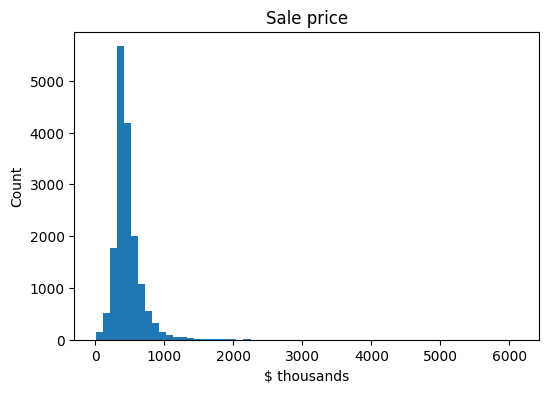

Price skewness: 6.42


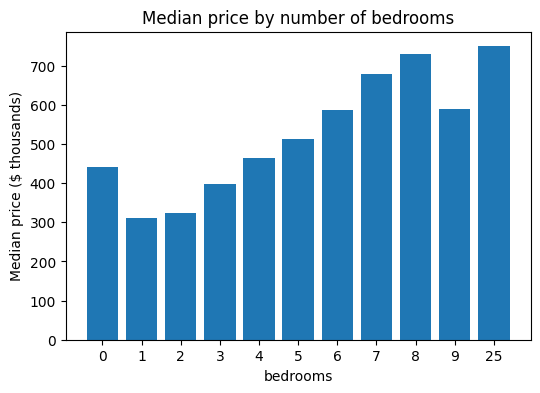

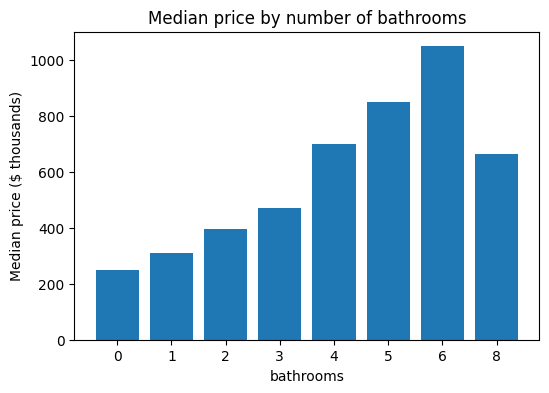

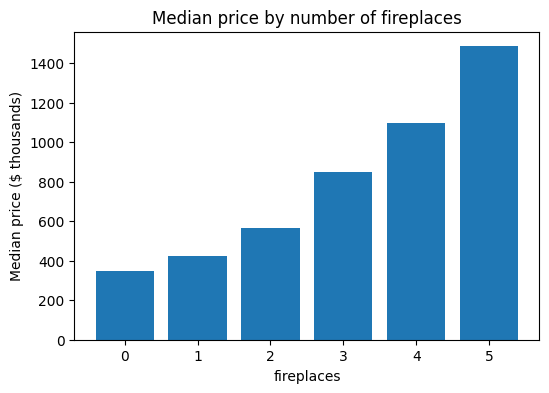

skewness: price = 6.42 log price = -0.86


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

sales = pd.read_csv('/content/pierce_county_house_sales.csv')

#Investigate Data
print(sales.shape)
print(sales.dtypes)
display(sales.head())
print(sales.columns.tolist())
print("duplicates:", sales.duplicated().sum()) #checking duplicates
print("missing:", sales.isna().sum())
display(sales.describe().T)


#Clean Data

sales['sale_date'] = pd.to_datetime(sales['sale_date']) #converting into real date type

#drop duplicate and missing values
sales = sales.drop_duplicates().dropna(subset=['hvac_description', 'exterior', 'interior', 'roof_cover'])

#filling blank with None in waterfront and view since house would have neither
sales[['waterfront_type', 'view_quality']] = sales[['waterfront_type', 'view_quality']].fillna('None')

#dropping implausible 0 story houses
sales = sales[sales.stories >= 1]

#fix inconsistent label
sales['hvac_description'] = sales['hvac_description'].replace('Floor Wall Furnace', 'Floor/Wall Furnace')
sales = sales.reset_index(drop=True)
print("Rows after cleaning:", len(sales))

#EDA

#price distribution
plt.figure(figsize=(6, 4))
plt.hist(sales.sale_price / 1e3, bins=60) #histogram of price in thousands and 60 bars
plt.title('Sale price'); plt.xlabel('$ thousands'); plt.ylabel('Count')
plt.show()
print("Price skewness:", round(sales.sale_price.skew(), 2)) #printing the skew

#price by bedroom, bathroon, fireplace count

for c in ['bedrooms', 'bathrooms', 'fireplaces']: #one graph for each of these
    med = sales.groupby(c)['sale_price'].median() / 1e3 #median price in thousands for each value of column
    plt.figure(figsize=(6, 4))
    plt.bar(med.index.astype(str), med.values)
    plt.title(f'Median price by number of {c}')
    plt.xlabel(c)
    plt.ylabel('Median price ($ thousands)')
    plt.show()

#transform variables for regression analysis

sales['log_price'] = np.log(sales['sale_price']) #log of the price, fixing skew
sales['log_sqft'] = np.log(sales['house_square_feet']) #log of house size
sales['age'] = (sales['sale_date'].dt.year - sales['year_built']).clip(lower=0) #house age at sales, negative ages set to 0
sales['waterfront'] = (sales['waterfront_type'] != 'None').astype(int) #1 if house has waterfront, 0 if not
sales['has_view'] = (sales['view_quality'] != 'None').astype(int) #1 if house has view, 0 if not

#checking log price is less skewed than raw price
print("skewness: price =", round(sales.sale_price.skew(), 2), "log price =", round(sales.log_price.skew(), 2))


#2.

In [ ]:
#calling the categorical variables to transform
categorical_vars = [
    "hvac_description",
    "exterior",
    "interior",
    "roof_cover",
    "waterfront_type",
    "view_quality",
    "utility_sewer"]

#keeping missing categories explicit rather than assuming their meaning
sales[categorical_vars] = sales[categorical_vars].fillna("Missing")

#converting categorical variables into numeric indicators (dummys)
sales_regression = pd.get_dummies(
    sales.drop(columns=["sale_date"]),
    columns=categorical_vars,
    drop_first=True,
    dtype=int)

#seperaing the outcome from the predictors
y = sales_regression["sale_price"]
X = sales_regression.drop(columns=["sale_price"])

X.head()

X = sales_regression.drop(columns=["sale_price", "log_price"])   #remove log_price so it can't leak the answer

#3.

In [ ]:
from sklearn.model_selection import train_test_split
#assigning 80% to training and 20% to testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=123)

#4.

Model 3, which includes house sqaure footages, bedrooms, bathrooms, year built. RSME test was lowest at about $178,983 and highest test R^2 at about 0.380.

In [ ]:
from sklearn.linear_model import LinearRegression
#import Linear Regress like in slides
sales_features_1 = ["house_square_feet"]
#run model 1, like in sldies
sk_fit_1 = LinearRegression().fit(X_train[sales_features_1], y_train)
#predict on train and test
train_pred = sk_fit_1.predict(X_train[sales_features_1])
test_pred = sk_fit_1.predict(X_test[sales_features_1])
#find RMSE and R^2 , test and train
print("Train RMSE:", np.sqrt(np.mean((y_train - train_pred)**2)))
print("Test RMSE:", np.sqrt(np.mean((y_test - test_pred)**2)))
print("Train R-squared:", sk_fit_1.score(X_train[sales_features_1], y_train))
print("Test R-squared:", sk_fit_1.score(X_test[sales_features_1], y_test))

Train RMSE: 201392.4100633626
Test RMSE: 183855.68594894744
Train R-squared: 0.26966162296006113
Test R-squared: 0.3453392417365111


In [ ]:
sales_features_2 = ["house_square_feet", "bedrooms", "bathrooms"]
#run model 2
sk_fit_2 = LinearRegression().fit(X_train[sales_features_2], y_train)
#predict on train and test, liek previous
train_pred = sk_fit_2.predict(X_train[sales_features_2])
test_pred = sk_fit_2.predict(X_test[sales_features_2])
#find RMSE and R^2 , test and train
print("Train RMSE:", np.sqrt(np.mean((y_train - train_pred)**2)))
print("Test RMSE:", np.sqrt(np.mean((y_test - test_pred)**2)))
print("Train R-squared:", sk_fit_2.score(X_train[sales_features_2], y_train))
print("Test R-squared:", sk_fit_2.score(X_test[sales_features_2], y_test))

Train RMSE: 198938.81710512989
Test RMSE: 180168.5803756458
Train R-squared: 0.28734885641780117
Test R-squared: 0.3713335393213967


In [ ]:
sales_features_3 = ["house_square_feet", "bedrooms", "bathrooms", "year_built"]
#run model 3
sk_fit_3 = LinearRegression().fit(X_train[sales_features_3], y_train)
#predict on train and test, liek previous
train_pred = sk_fit_3.predict(X_train[sales_features_3])
test_pred = sk_fit_3.predict(X_test[sales_features_3])
#find RMSE and R^2 , test and train
print("Train RMSE:", np.sqrt(np.mean((y_train - train_pred)**2)))
print("Test RMSE:", np.sqrt(np.mean((y_test - test_pred)**2)))
print("Train R-squared:", sk_fit_3.score(X_train[sales_features_3], y_train))
print("Test R-squared:", sk_fit_3.score(X_test[sales_features_3], y_test))

Train RMSE: 197754.81988313515
Test RMSE: 178983.15866604258
Train R-squared: 0.29580639215575455
Test R-squared: 0.3795789639940097


#5.

The partial correlaiton plots do not show any strong obvious nonlinearities. The year built may shows some curvature. Footage shows a generally positive relationship with price, and bedrooms show a generally negative relationship with price after controlling for the other predictors. Many had large outliers and uneven spreads make the pattern a challenge to assess, meaning a linear model is reasonable start point.


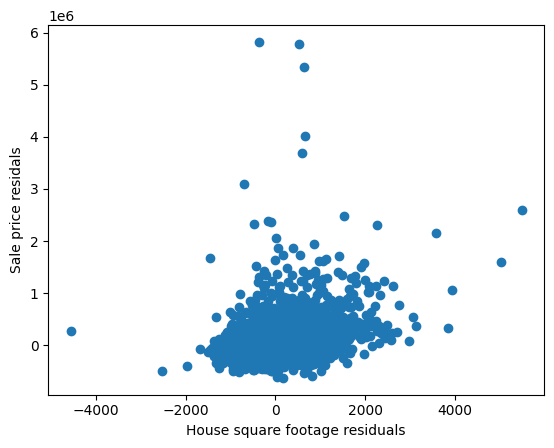

In [ ]:
#partial correlation plot for house square footage
#other 3 predictors to control
controls_sft = ["bedrooms", "bathrooms", "year_built"]
#predict price using other 3 predictors
price_fit = LinearRegression().fit(X_train[controls_sft], y_train)
#predict square footage using other 3 predictors
variable_fit = LinearRegression().fit(
    X_train[controls_sft], X_train["house_square_feet"])
#remove price variation predicted by the other predictors
r_price = y_train - price_fit.predict(X_train[controls_sft])
#remove square footage variation predicted by the other predictors
r_variable = X_train["house_square_feet"] - variable_fit.predict(X_train[controls_sft])
#plot remaining relationship between square footage and price
plt.scatter(r_variable, r_price)
plt.xlabel("House square footage residuals")
plt.ylabel("Sale price residals")
plt.show()

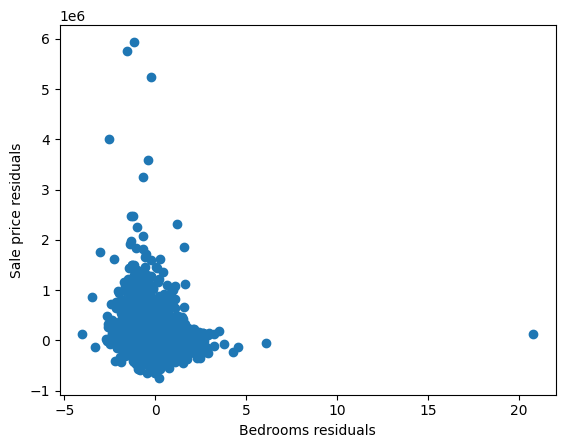

In [ ]:
#partial correlation plot for bedrooms
#other 3 predictors to control
controls_bedroom = ["house_square_feet", "bathrooms", "year_built"]
#predict price using other 3 predictors
price_fit = LinearRegression().fit(X_train[controls_bedroom], y_train)
#predict bedrooms using other 3 predictors
variable_fit = LinearRegression().fit(
    X_train[controls_bedroom], X_train["bedrooms"])
#remove price variation predicted by the other predictors
r_price = y_train - price_fit.predict(X_train[controls_bedroom])
#remove bedrooms variation predicted by the other predictors
r_variable = X_train["bedrooms"] - variable_fit.predict(X_train[controls_bedroom])
#plot remaining relationship between bedrooms and price
plt.scatter(r_variable, r_price)
plt.xlabel("Bedrooms residuals")
plt.ylabel("Sale price residuals")
plt.show()

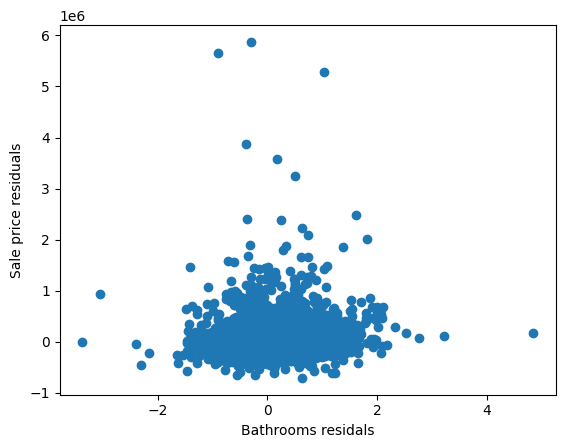

In [ ]:
#partial correlation plot for bathrooms
#other 3 predictors to control for
controls_bathrooms = ["house_square_feet", "bedrooms", "year_built"]
#predict price using other 3 predictors
price_fit = LinearRegression().fit(X_train[controls_bathrooms], y_train)
#predict bathrooms using other 3 predictors
variable_fit = LinearRegression().fit(
    X_train[controls_bathrooms], X_train["bathrooms"])
#remove price variation predicted by the other predictors
r_price = y_train - price_fit.predict(X_train[controls_bathrooms])
#remove bathrooms variation predicted by the other predictors
r_variable = X_train["bathrooms"] - variable_fit.predict(X_train[controls_bathrooms])
#plot remaining relationship between bathrooms and price
plt.scatter(r_variable, r_price)
plt.xlabel("Bathrooms residals")
plt.ylabel("Sale price residuals")
plt.show()

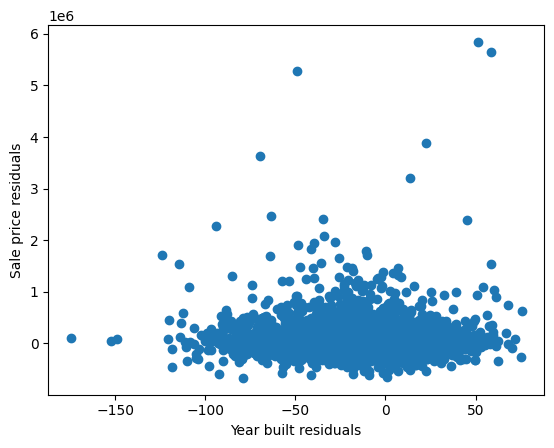

In [ ]:
#partial correlation plot for year built
#other 3 predictors to control for
controls_yr = ["house_square_feet", "bedrooms", "bathrooms"]
#predict price using other 3 predictors
price_fit = LinearRegression().fit(X_train[controls_yr], y_train)
#predict year built using other 3 predictors
variable_fit = LinearRegression().fit(
    X_train[controls_yr], X_train["year_built"])
#remove price variation predicted by the other predictors
r_price = y_train - price_fit.predict(X_train[controls_yr])
#remove year built variation predicted by the other predictors
r_variable = X_train["year_built"] - variable_fit.predict(X_train[controls_yr])
#plot remaining relationship between year built and price
plt.scatter(r_variable, r_price)
plt.xlabel("Year built residuals")
plt.ylabel("Sale price residuals")
plt.show()

#6.

The complex model from # 6 has a training RMSE of 192867 and training R^2 of 0.3302. Its test RMSE is 170,034 and test R^2 is 0.4401. 0). Compared to Model 3, it performs better on both datasets. The addition of squared terms and interactions improved predictive performance, with no indication that the added complexity hurt test performance.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
#add squared terms and interactions to model 3s predictors
expander = PolynomialFeatures(degree=2, include_bias=False)
#fit transformation using training data
X_train_complex = expander.fit_transform(X_train[sales_features_3])
#apply same transformation to test data
X_test_complex = expander.transform(X_test[sales_features_3])
#fit more complex model
sk_fit_4 = LinearRegression().fit(X_train_complex, y_train)
#predict on training and test data
train_pred = sk_fit_4.predict(X_train_complex)
test_pred = sk_fit_4.predict(X_test_complex)
#find RMSE for training and test data
print("Train RMSE:", np.sqrt(np.mean((y_train - train_pred)**2)))
print("Test RMSE:", np.sqrt(np.mean((y_test - test_pred)**2)))
#find R-squared for training and test data
print("Train R-squared:", sk_fit_4.score(X_train_complex, y_train))
print("Test R-squared:", sk_fit_4.score(X_test_complex, y_test))

Train RMSE: 192866.9219391454
Test RMSE: 170033.63686491418
Train R-squared: 0.3301872307588488
Test R-squared: 0.44007241146986076


#7.

We cleaned the data by removing duplicates, rows with missing information in selected columns, and zero-story houses. We also explored log transformations to address the right-skewed price distribution. Among the simple models, test RMSE decreased from 183,856 to 180,169 to 178,983 as variables were added, making Model 3 the strongest. The complex model, which included squared terms and interactions, further improved test RMSE to 170,034 (R squaured = 0.440).

We noticed that the training error was higher than test error across all models, suggesting the two samples differed in difficulty. We learned that training error alone does not measure how well a model predicts unseen data. Models should be evaluated using validation sets or cross-validation, with the test set reserved for final evaluation. Increasing model complexity can improve predictive performance, but models should be evaluated on unseen data to ensure those improvements generalize.

#8.

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import root_mean_squared_error

#creating Lasso model with scaled predictors
def lasso_model(alpha):
    return make_pipeline(
        MinMaxScaler(feature_range=(-1, 1)),
        Lasso(alpha=alpha, max_iter=100000))

#using cross-validation to select the best alpha
alphas = [10, 30, 100, 300, 1000, 3000, 10000]
folds = KFold(n_splits=5, shuffle=True, random_state=123)

cv_errors = []

for alpha in alphas:
    scores = cross_val_score(
        lasso_model(alpha),
        X_train,
        y_train,
        cv=folds,
        scoring='neg_root_mean_squared_error')
    cv_errors.append(-scores.mean())

#select the alpha with the lowest cross-validation error
best_alpha = alphas[np.argmin(cv_errors)]
print("Best alpha:", best_alpha)

#fiting final model using all training data
final_model = lasso_model(best_alpha)
final_model.fit(X_train, y_train)

#evaluate model
train_pred = final_model.predict(X_train)
test_pred = final_model.predict(X_test)

print("train RMSE:", round(root_mean_squared_error(y_train, train_pred)))
print("test RMSE:", round(root_mean_squared_error(y_test, test_pred)))
print("train R-squared:", round(final_model.score(X_train, y_train), 3))
print("test R-squared:", round(final_model.score(X_test, y_test), 3))

#identify features selected by Lasso
coefficients = pd.Series(final_model[-1].coef_, index=X_train.columns)

selected_features = coefficients[coefficients != 0].sort_values(key=abs, ascending=False)

print("\nFeatures selected:", len(selected_features))
print(selected_features.round(0))

Best alpha: 10
train RMSE: 160260
test RMSE: 147555
train R-squared: 0.538
test R-squared: 0.578

Features selected: 51
house_square_feet                       995813.0
log_sqft                               -622896.0
utility_sewer_SEWER/SEPTIC NO PERC     -481002.0
utility_sewer_SEWER/SEPTIC NO          -383961.0
exterior_Log                            344152.0
waterfront_type_WF Salt                 294613.0
exterior_Unfinished Cottage             267348.0
utility_sewer_SEWER/SEPTIC INSTALLED   -260538.0
exterior_Pine Finished Cabin            244322.0
bedrooms                               -237689.0
utility_sewer_SEWER/SEPTIC AVAIL       -230009.0
exterior_Frame Rustic Log               209394.0
basement_square_feet                    182609.0
exterior_Cedar Unfinished Cabin         181566.0
waterfront_type_WF Lake                 174938.0
view_quality_View V-Good                164304.0
detached_garage_square_feet             128414.0
attached_garage_square_feet              94136.

Cross-validation selected alpha = 10, which retained 51 of the 58 features. The model achieved a training RMSE of $160,260 (R sqaured = 0.538) and a test RMSE of $147,555 (R squared = 0.578). Some of the strongest features included house square footage, log square footage, basement size, bedrooms, and waterfront categories. Lasso performed better than all three simple models and the complex model on the test set.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]